# 1. Prueba diagnóstica

Suponga una enfermedad con prevalencia 1%, sensibilidad 95% y especificidad 90%.

In [8]:
prior <- 0.01
sens <- 0.95
esp  <- 0.90

p_pos <- sens * prior + (1 - esp) * (1 - prior)
p_enf_pos <- sens * prior / p_pos
p_enf_pos

[1] 0.0875576

# 2. Modelo Beta-Binomial

Queremos estimar la proporción real de estudiantes que aprueban un módulo.

Datos observados: 14 aprobados de 20 estudiantes.

Priori: $\theta \sim Beta(2,2)$.

In [9]:
y <- 14
n <- 20
alpha <- 2
beta <- 2

alpha_post <- alpha + y
beta_post <- beta + n - y

c(alpha_post = alpha_post, beta_post = beta_post)

alpha_post  beta_post 
        16          8

In [10]:
media_post <- alpha_post / (alpha_post + beta_post)
ic_95 <- qbeta(c(0.025, 0.975), alpha_post, beta_post)

media_post
ic_95

[1] 0.6666667

[1] 0.4708083 0.8362364

# 3. Visualización de priori y posteriori

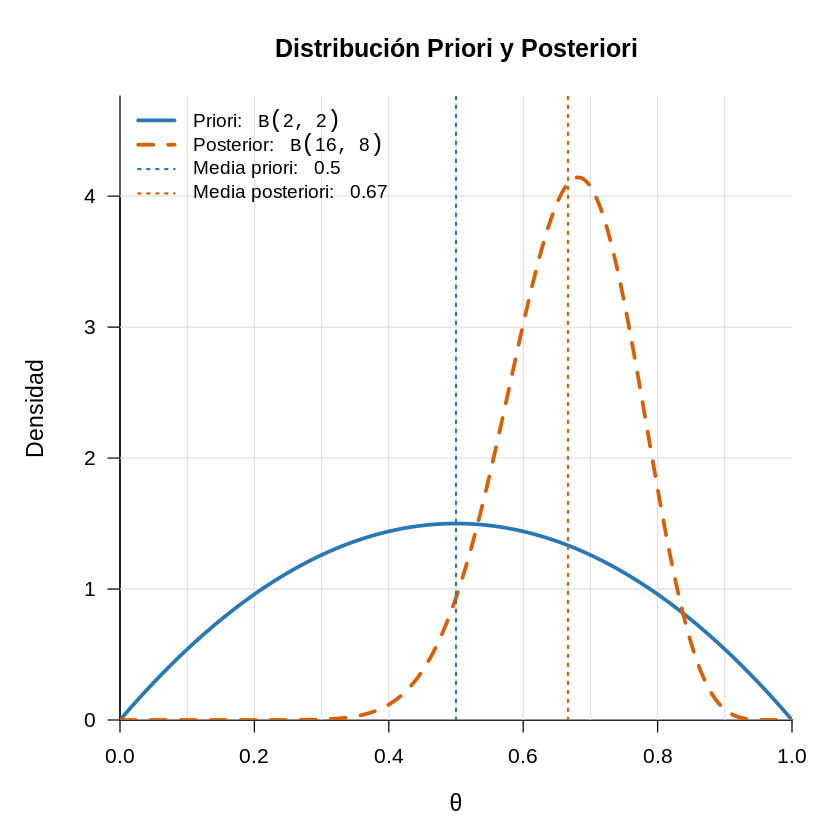

In [11]:
# Parámetros
alpha <- 2
beta  <- 2

alpha_post <- 16
beta_post  <- 8

# Valores posibles de theta
theta <- seq(0.001, 0.999, length.out = 2000)

# Densidades
prior <- dbeta(theta, alpha, beta)
post  <- dbeta(theta, alpha_post, beta_post)

# Medias
media_prior <- alpha / (alpha + beta)
media_post  <- alpha_post / (alpha_post + beta_post)

# Colores
color_prior <- "#2878B5"
color_post  <- "#D95F02"

# Límite superior dinámico para mostrar ambas curvas completas
limite_y <- 1.15 * max(prior, post)

# Márgenes y estilo general
par(
  mar = c(5, 5, 4, 2),
  las = 1,
  bty = "l",
  cex.axis = 1.05,
  cex.lab = 1.15,
  cex.main = 1.25
)

# Crear primero el lienzo vacío
plot(
  theta, prior,
  type = "n",
  xlim = c(0, 1),
  ylim = c(0, limite_y),
  xaxs = "i",
  yaxs = "i",
  xlab = expression(theta),
  ylab = "Densidad",
  main = "Distribución Priori y Posteriori"
)

# Cuadrícula
grid(
  nx = 10,
  ny = NULL,
  col = "gray88",
  lty = 1
)

# Curvas
lines(
  theta, prior,
  col = color_prior,
  lwd = 3
)

lines(
  theta, post,
  col = color_post,
  lwd = 3,
  lty = 2
)

# Medias de las distribuciones
abline(
  v = media_prior,
  col = color_prior,
  lwd = 1.8,
  lty = 3
)

abline(
  v = media_post,
  col = color_post,
  lwd = 1.8,
  lty = 3
)

# Leyenda
legend(
  "topleft",
  legend = c(
    expression("Priori: " ~ Beta(2,2)),
    expression("Posterior: " ~ Beta(16,8)),
    expression("Media priori: " ~ 0.50),
    expression("Media posteriori: " ~ 0.67)
  ),
  col = c(color_prior, color_post, color_prior, color_post),
  lty = c(1, 2, 3, 3),
  lwd = c(3, 3, 1.8, 1.8),
  bty = "n",
  cex = 0.95
)

# 4. Probabilidad posterior por simulación

Calculemos $P(\theta > 0.6 \mid y)$.


In [12]:
set.seed(123)
S <- 10000
theta_sim <- rbeta(S, alpha_post, beta_post)
mean(theta_sim > 0.6)

[1] 0.7581

# 5. Sensibilidad a la priori

Comparamos tres prioris distintas.

In [13]:
prioris <- data.frame(
  nombre = c("Uniforme", "Moderada centrada en 0.5", "Optimista"),
  alpha = c(1, 2, 8),
  beta = c(1, 2, 2)
)

resultados <- data.frame()

for (i in 1:nrow(prioris)) {
  a_post <- prioris$alpha[i] + y
  b_post <- prioris$beta[i] + n - y
  resultados <- rbind(resultados, data.frame(
    previa = prioris$nombre[i],
    alpha_post = a_post,
    beta_post = b_post,
    media_posteriori = a_post / (a_post + b_post),
    LI_95 = qbeta(0.025, a_post, b_post),
    LS_95 = qbeta(0.975, a_post, b_post),
    prob_mayor_06 = 1 - pbeta(0.6, a_post, b_post)
  ))
}

resultados

previa,alpha_post,beta_post,media_posteriori,LI_95,LS_95,prob_mayor_06
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Uniforme,15,7,0.6818182,0.4782489,0.8541231,0.7997540
Moderada centrada en 0.5,16,8,0.6666667,0.4708083,0.8362364,0.7627291
Optimista,22,8,0.7333333,0.5645997,0.8726599,0.9430127


# 6. Ejercicio para los estudiantes

Cambie los datos a 8 aprobados de 20 estudiantes y repita el análisis.

Preguntas:

1. ¿La posterior cambia mucho respecto al caso anterior?

2. ¿Qué previa tiene mayor influencia?

3. ¿Cómo comunicaría el resultado a una persona no estadística?

